# Customer Churn Prediction

End-to-end binary classification project: predict whether a telecom customer is likely to **churn** (leave the company) or stay.

> This notebook is a rebuild of the project I developed during my Machine Learning internship at NexAfrica, recreated from scratch using the public Telco Customer Churn dataset.

**Workflow:** Business Understanding → Data Collection → Data Understanding → Data Cleaning → EDA → Feature Engineering → Preprocessing → Modeling → Evaluation → Class Imbalance → Tuning → Final Model → Feature Importance → Business Insights → Recommendations

_Status: sections 1-4 (Week 1) are complete. The remaining sections are added in later weeks._

## 1. Business Understanding

**What is customer churn?**
Churn happens when a customer stops using a company's service. In a telecom company it means a customer cancels their plan or does not renew.

**Why does it matter?**
It is generally cheaper to keep an existing customer than to acquire a new one. A high churn rate reduces recurring revenue, so even a small improvement in retention can have a large financial impact.

**Goal of the model**
Predict, from demographic, account, service and billing information, whether a customer is likely to churn.

**How can predicting churn help?**
The company can identify high-risk customers *before* they leave and act on them: retention offers, contract upgrades, proactive support or loyalty programs, focusing the budget where it matters most.

**Problem statement**
> The objective of this project is to develop a Machine Learning classification model that predicts whether a customer is likely to churn based on demographic information, account details, subscription information, service usage, contract type, tenure, and billing information.

- **Problem type:** supervised learning, binary classification
- **Target variable:** `Churn` (Yes / No)

In [2]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# Make the project's src/ package importable from the notebook
sys.path.append(str(Path.cwd().parent / "src"))

from churn.config import PROCESSED_DATA_PATH, TARGET, VISUALS_DIR
from churn.data.cleaning import clean_data, quality_report
from churn.data.loader import describe_structure, load_raw_data, target_distribution

pd.set_option("display.max_columns", None)

## 2. Data Collection

The data comes from the public **Telco Customer Churn** dataset (IBM sample data, also available on Kaggle): one row per customer of a fictional telecom company. The raw file is stored unmodified in `data/raw_data/telco_churn.csv`.

In [5]:
df_raw = load_raw_data()
describe_structure(df_raw)

Rows:    7,043
Columns: 21

Column names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Data types:
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object


In [6]:
df_raw.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 3. Data Understanding

A description of every variable is available in [`docs/data_dictionary.md`](../docs/data_dictionary.md).

- **Target variable:** `Churn`
- **Identifier:** `customerID` (unique per customer, not used as a predictor)
- **Features:** the other 19 columns: demographics, services, contract, billing and tenure

In [8]:
df_raw.describe().round(2)

,SeniorCitizen,tenure,MonthlyCharges
count,7043.00,7043.00,7043.00
mean,0.16,32.37,64.76
std,0.37,24.56,30.09
min,0.00,0.00,18.25
25%,0.00,9.00,35.50
50%,0.00,29.00,70.35
75%,0.00,55.00,89.85
max,1.00,72.00,118.75


In [9]:
df_raw.select_dtypes(include="object").nunique().sort_values()

Churn                  2
gender                 2
Partner                2
Dependents             2
PhoneService           2
PaperlessBilling       2
Contract               3
StreamingMovies        3
StreamingTV            3
TechSupport            3
OnlineBackup           3
OnlineSecurity         3
InternetService        3
MultipleLines          3
DeviceProtection       3
PaymentMethod          4
TotalCharges        6531
customerID          7043
dtype: int64

## 4. Data Cleaning

### 4.1 Missing values and blank strings

In [10]:
quality_report(df_raw)

,dtype,missing,blank_strings,unique_values
Churn,object,0,0,2
Contract,object,0,0,3
Dependents,object,0,0,2
DeviceProtection,object,0,0,3
InternetService,object,0,0,3
MonthlyCharges,float64,0,0,1585
MultipleLines,object,0,0,3
OnlineBackup,object,0,0,3
OnlineSecurity,object,0,0,3
PaperlessBilling,object,0,0,2


There are no `NaN` values, but **`TotalCharges` is stored as text (`object`)** even though it should be numeric. The reason is hidden in blank strings:

In [11]:
blank_total = df_raw[df_raw["TotalCharges"].str.strip() == ""]
blank_total[["customerID", "tenure", "MonthlyCharges", "TotalCharges"]]

,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,
753,3115-CZMZD,0,20.25,
936,5709-LVOEQ,0,80.85,
1082,4367-NUYAO,0,25.75,
1340,1371-DWPAZ,0,56.05,
3331,7644-OMVMY,0,19.85,
3826,3213-VVOLG,0,25.35,
4380,2520-SGTTA,0,20.00,
5218,2923-ARZLG,0,19.70,
6670,4075-WKNIU,0,73.35,


There are **11 blank values** and all of them belong to customers with `tenure = 0`: new customers who have not been billed yet. The correct value for them is `0`, so they are filled with `0` rather than dropped.

### 4.2 Duplicate records

In [8]:
print(f"Duplicate rows:        {df_raw.duplicated().sum()}")
print(f"Duplicate customerIDs: {df_raw['customerID'].duplicated().sum()}")

Duplicate rows:        0
Duplicate customerIDs: 0


No duplicate rows or duplicate customers.

### 4.3 Inconsistent values in categorical variables

In [9]:
for col in df_raw.select_dtypes(include="object").columns.drop(["customerID", "TotalCharges"]):
    print(f"{col:18s} {sorted(df_raw[col].unique())}")

gender             ['Female', 'Male']
Partner            ['No', 'Yes']
Dependents         ['No', 'Yes']
PhoneService       ['No', 'Yes']
MultipleLines      ['No', 'No phone service', 'Yes']
InternetService    ['DSL', 'Fiber optic', 'No']
OnlineSecurity     ['No', 'No internet service', 'Yes']
OnlineBackup       ['No', 'No internet service', 'Yes']
DeviceProtection   ['No', 'No internet service', 'Yes']
TechSupport        ['No', 'No internet service', 'Yes']
StreamingTV        ['No', 'No internet service', 'Yes']
StreamingMovies    ['No', 'No internet service', 'Yes']
Contract           ['Month-to-month', 'One year', 'Two year']
PaperlessBilling   ['No', 'Yes']
PaymentMethod      ['Bank transfer (automatic)', 'Credit card (automatic)', 'Electronic check', 'Mailed check']
Churn              ['No', 'Yes']


No spelling mistakes, capitalization problems or stray spaces. There are, however, three consistency issues:

1. `SeniorCitizen` is encoded as `0/1` while every other binary column uses `Yes/No`.
2. Six add-on columns (`OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport`, `StreamingTV`, `StreamingMovies`) contain the category `No internet service`, which duplicates the information already in `InternetService`.
3. `MultipleLines` contains `No phone service`, which duplicates `PhoneService`.

### 4.4 Applying the cleaning
The logic lives in `src/churn/data/cleaning.py` (function `clean_data`), so it is reusable outside the notebook:

1. Strip whitespace in text columns
2. Drop duplicate rows / customers
3. Convert `TotalCharges` to numeric (blank → `0` for customers with `tenure = 0`)
4. Convert `SeniorCitizen` from `0/1` to `No/Yes`
5. Merge `No internet service` and `No phone service` into `No`

In [10]:
df = clean_data(df_raw)
quality_report(df)

,dtype,missing,blank_strings,unique_values
Churn,object,0,0,2
Contract,object,0,0,3
Dependents,object,0,0,2
DeviceProtection,object,0,0,2
InternetService,object,0,0,3
MonthlyCharges,float64,0,0,1585
MultipleLines,object,0,0,2
OnlineBackup,object,0,0,2
OnlineSecurity,object,0,0,2
PaperlessBilling,object,0,0,2


In [11]:
PROCESSED_DATA_PATH.parent.mkdir(parents=True, exist_ok=True)
df.to_csv(PROCESSED_DATA_PATH, index=False)
print(f"Saved cleaned dataset: {df.shape[0]:,} rows x {df.shape[1]} columns")

Saved cleaned dataset: 7,043 rows x 21 columns


### 4.5 Target variable distribution

In [13]:
dist = target_distribution(df)
dist

NameError: name 'df' is not defined

NameError: name 'dist' is not defined

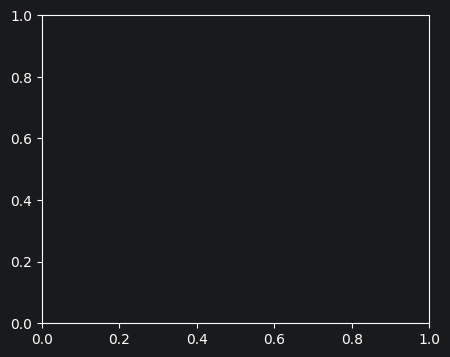

In [12]:
VISUALS_DIR.mkdir(exist_ok=True)

fig, ax = plt.subplots(figsize=(5, 4))
bars = ax.bar(dist.index, dist["count"], color=["#4C72B0", "#DD8452"])
for bar, pct in zip(bars, dist["percentage"]):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 50, f"{pct}%", ha="center")
ax.set_title("Customer churn distribution")
ax.set_xlabel("Churn")
ax.set_ylabel("Number of customers")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(VISUALS_DIR / "target_distribution.png", dpi=150)
plt.show()

**Observations**

- **26.54%** of customers churned (1,869) versus **73.46%** who stayed (5,174), roughly a 2.8 : 1 ratio. The dataset is **moderately imbalanced**.
- A model that always predicts "No churn" would already reach about 73% accuracy without detecting a single churner. **Accuracy alone is therefore misleading**, and models will be compared using Precision, Recall, F1-score and ROC-AUC.
- The train/test split will be **stratified** to keep this class proportion, and imbalance-handling techniques will be tested in Week 4.

---
_Next: Week 2, Exploratory Data Analysis and Feature Engineering._